In [1]:
from pathlib import Path
from time import perf_counter
import struct
import numpy as np
import matplotlib.pyplot as plt


DATA_DIR = Path(r'D:\Глубокое обучение\Лабораторные работы\Лабораторная работа 1')
SEED = 42
HIDDEN_SIZE = 300
LEARNING_RATE = 0.1
BATCH_SIZE = 64
EPOCHS = 20


##  Загрузка и подготовка MNIST




In [2]:
def read_idx(path):
    raw = Path(path).read_bytes()
    magic = struct.unpack('>I', raw[:4])[0]

    if magic == 2051:
        shape = struct.unpack('>III', raw[4:16])
        header_size = 16
    elif magic == 2049:
        shape = struct.unpack('>I', raw[4:8])
        header_size = 8
    else:
        raise ValueError(f'Неизвестный тип файла MNIST: {path}')

    return np.frombuffer(
        raw, dtype=np.uint8, offset=header_size
    ).reshape(shape)

train_images = read_idx(DATA_DIR / 'train-images.idx3-ubyte')
y_train = read_idx(DATA_DIR / 'train-labels.idx1-ubyte').astype(np.int64)

test_images = read_idx(DATA_DIR / 't10k-images.idx3-ubyte')
y_test = read_idx(DATA_DIR / 't10k-labels.idx1-ubyte').astype(np.int64)

assert train_images.shape == (60000, 28, 28) and y_train.shape == (60000,)
assert test_images.shape == (10000, 28, 28) and y_test.shape == (10000,)
assert np.all((y_train >= 0) & (y_train <= 9))
assert np.all((y_test >= 0) & (y_test <= 9))

X_train = train_images.reshape(-1, 784).astype(np.float32) / 255.0
X_test = test_images.reshape(-1, 784).astype(np.float32) / 255.0

print('Изображения train:', train_images.shape, '→', X_train.shape)
print('Изображения test: ', test_images.shape, '→', X_test.shape)
print('Метки train:', y_train.shape)
print('Метки test: ', y_test.shape)
print('Одно изображение:', train_images[0].shape)
print('Одна метка:', y_train[0], '— скаляр, форма', y_train[0].shape)
print('Диапазон яркостей:', X_train.min(), '—', X_train.max())


Изображения train: (60000, 28, 28) → (60000, 784)
Изображения test:  (10000, 28, 28) → (10000, 784)
Метки train: (60000,)
Метки test:  (10000,)
Одно изображение: (28, 28)
Одна метка: 5 — скаляр, форма ()
Диапазон яркостей: 0.0 — 1.0


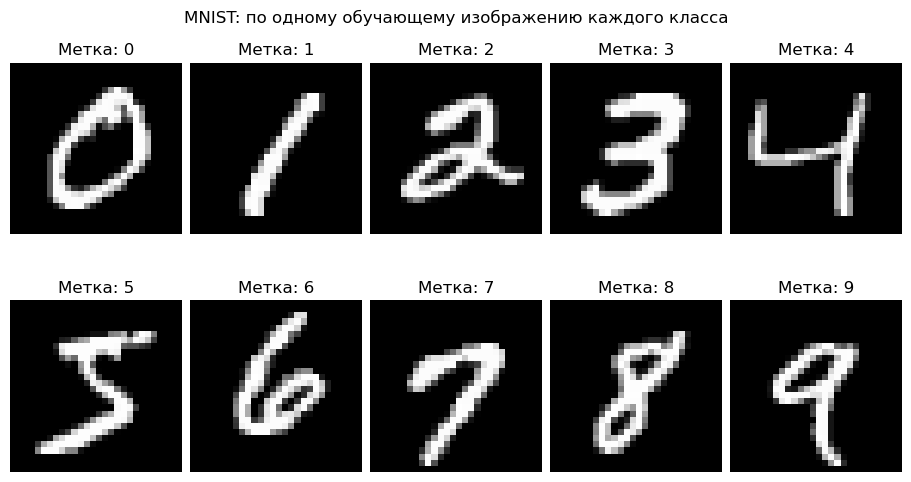

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(9, 5), layout='constrained')
for digit, ax in enumerate(axes.flat):
    index = np.flatnonzero(y_train == digit)[0]
    ax.imshow(train_images[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Метка: {digit}')
    ax.axis('off')
fig.suptitle('MNIST: по одному обучающему изображению каждого класса')
plt.show()


##  Реализация сети



In [4]:
def init_parameters(input_size, hidden_size, output_size, rng, dtype=np.float32):
    return {
        'W1': (rng.standard_normal((input_size, hidden_size)) * np.sqrt(2 / input_size)).astype(dtype),
        'b1': np.zeros(hidden_size, dtype=dtype),
        'W2': (rng.standard_normal((hidden_size, output_size)) / np.sqrt(hidden_size)).astype(dtype),
        'b2': np.zeros(output_size, dtype=dtype),
    }


def log_softmax(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)
    return shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))


def forward(X, params):
    Z1 = X @ params['W1'] + params['b1']
    H = np.maximum(Z1, 0)
    Z2 = H @ params['W2'] + params['b2']
    return log_softmax(Z2), (Z1, H)


def loss_and_gradients(X, y, params):
    log_probs, (Z1, H) = forward(X, params)
    batch_size = len(y)
    loss = -log_probs[np.arange(batch_size), y].mean()
    D2 = np.exp(log_probs)
    D2[np.arange(batch_size), y] -= 1
    D2 /= batch_size
    D1 = (D2 @ params['W2'].T) * (Z1 > 0)
    gradients = {
        'W1': X.T @ D1,
        'b1': D1.sum(axis=0),
        'W2': H.T @ D2,
        'b2': D2.sum(axis=0),
    }
    return float(loss), gradients


def sgd_step(params, gradients, learning_rate):
    for name in params:
        params[name] -= learning_rate * gradients[name]


def evaluate(X, y, params, batch_size=1024):
    total_loss = 0.0
    predictions = np.empty(len(y), dtype=np.int64)
    for start in range(0, len(y), batch_size):
        stop = min(start + batch_size, len(y))
        log_probs, _ = forward(X[start:stop], params)
        total_loss -= float(log_probs[np.arange(stop-start), y[start:stop]].sum(dtype=np.float64))
        predictions[start:stop] = log_probs.argmax(axis=1)
    errors = int(np.count_nonzero(predictions != y))
    return {'loss': total_loss / len(y), 'error': errors / len(y),
            'accuracy': 1 - errors / len(y), 'errors': errors}, predictions


## Обучение




In [5]:
params = init_parameters(
    784, HIDDEN_SIZE, 10, np.random.default_rng(SEED)
)
shuffle_rng = np.random.default_rng(SEED + 1)

training_start = perf_counter()
print('Эпоха | Train CE | Ошибка, % | Точность, % | Время, с', flush=True)

for epoch in range(1, EPOCHS + 1):
    epoch_start = perf_counter()
    order = shuffle_rng.permutation(len(y_train))

    for start in range(0, len(order), BATCH_SIZE):
        indices = order[start:start + BATCH_SIZE]

        _, gradients = loss_and_gradients(
            X_train[indices], y_train[indices], params
        )
        sgd_step(params, gradients, LEARNING_RATE)

    train_metrics, _ = evaluate(X_train, y_train, params)
    epoch_seconds = perf_counter() - epoch_start

    print(
        f"{epoch:5d} | {train_metrics['loss']:8.5f} | "
        f"{100 * train_metrics['error']:9.3f} | "
        f"{100 * train_metrics['accuracy']:11.3f} | "
        f"{epoch_seconds:8.2f}",
        flush=True
    )

training_seconds = perf_counter() - training_start
print(f'Общее время обучения с оценкой train: {training_seconds:.2f} с')

Эпоха | Train CE | Ошибка, % | Точность, % | Время, с
    1 |  0.23082 |     6.463 |      93.537 |     0.56
    2 |  0.15818 |     4.427 |      95.573 |     0.56
    3 |  0.12288 |     3.442 |      96.558 |     0.56
    4 |  0.09871 |     2.765 |      97.235 |     0.57
    5 |  0.08319 |     2.287 |      97.713 |     0.56
    6 |  0.07248 |     2.028 |      97.972 |     0.57
    7 |  0.06029 |     1.592 |      98.408 |     0.56
    8 |  0.06843 |     1.958 |      98.042 |     0.58
    9 |  0.04771 |     1.217 |      98.783 |     0.58
   10 |  0.04351 |     1.093 |      98.907 |     0.59
   11 |  0.03909 |     0.942 |      99.058 |     0.56
   12 |  0.03469 |     0.832 |      99.168 |     0.60
   13 |  0.03178 |     0.737 |      99.263 |     0.60
   14 |  0.02894 |     0.610 |      99.390 |     0.59
   15 |  0.02658 |     0.550 |      99.450 |     0.59
   16 |  0.02351 |     0.428 |      99.572 |     0.56
   17 |  0.02171 |     0.390 |      99.610 |     0.60
   18 |  0.02034 |     0.347

##  Оценка на тестовой выборке



In [6]:
test_metrics, _ = evaluate(X_test, y_test, params)

print(f"Кросс-энтропия на test: {test_metrics['loss']:.6f}")
print(f"Ошибка классификации на test: {100*test_metrics['error']:.2f}%")
print(f"Точность на test: {100*test_metrics['accuracy']:.2f}%")
print(f"Неверных ответов: {test_metrics['errors']} из {len(y_test)}")


Кросс-энтропия на test: 0.063181
Ошибка классификации на test: 1.92%
Точность на test: 98.08%
Неверных ответов: 192 из 10000
